# TrendPulse — Part 3: Visualization, EDA & Business Thinking

**Objective:** turn the US, GB and IN trending-video snapshots into an evidence-backed content strategy briefing. This notebook is self-contained and uses only local CSV files.

Run top to bottom. The analysis is rule-based; no machine learning, API calls, scraping or external services are used.

## 1. Imports and configuration

The notebook expects `data/` beside this notebook. If your Colab upload location differs, change `DATA_DIR` below.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("data")
COUNTRIES = ["US", "GB", "IN"]
FILES = {c: DATA_DIR / f"{c}videos.csv" for c in COUNTRIES}
CATEGORY_FILE = DATA_DIR / "categories.csv"
missing_files = [str(p) for p in list(FILES.values()) + [CATEGORY_FILE] if not p.exists()]
if missing_files:
    raise FileNotFoundError("Required data file(s) not found: " + ", ".join(missing_files) + ". Keep the data folder beside this notebook or update DATA_DIR.")
print("All four input files found.")

All four input files found.


## 2. Load, profile and clean the data

Inspect source columns before transformation. Country is retained as a dimension. `trending_date` in this dataset is commonly encoded as `YY.DD.MM`, so it is parsed explicitly.

In [2]:
raw_frames = []
source_profiles = {}
for country, path in FILES.items():
    frame = pd.read_csv(path, low_memory=False)
    source_profiles[country] = {"shape": frame.shape, "columns": list(frame.columns)}
    frame["country"] = country
    raw_frames.append(frame)
    print(f"{country}: shape={frame.shape}")
    print("Columns:", list(frame.columns))

raw = pd.concat(raw_frames, ignore_index=True, sort=False)
categories = pd.read_csv(CATEGORY_FILE)
print("\nCombined raw shape:", raw.shape)
print("Category lookup shape:", categories.shape)
print("\nRaw data types:")
display(raw.dtypes.astype(str).rename("dtype").to_frame())

# Missingness is profiled before cleaning, for every column affected.
missing_pct = (raw.isna().mean().mul(100).loc[lambda s: s.gt(0)].sort_values(ascending=False))
print("\nMissing-value percentage by affected column (raw combined data):")
if missing_pct.empty:
    print("No missing values found.")
else:
    display(missing_pct.rename("missing_percent").to_frame().round(2))

required = {"video_id", "trending_date", "publish_time", "category_id", "views", "likes", "dislikes", "comment_count"}
missing_required = required - set(raw.columns)
if missing_required:
    raise ValueError(f"Input data is missing required columns: {sorted(missing_required)}")

clean = raw.copy()
clean["trending_date"] = pd.to_datetime(clean["trending_date"].astype(str), format="%y.%d.%m", errors="coerce")
clean["publish_time"] = pd.to_datetime(clean["publish_time"], errors="coerce", utc=True)
for col in ["category_id", "views", "likes", "dislikes", "comment_count"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
for col in ["comments_disabled", "ratings_disabled", "video_error_or_removed"]:
    if col in clean.columns:
        clean[col] = clean[col].astype(str).str.strip().str.lower().map({"true": True, "false": False, "1": True, "0": False})

start_rows = len(clean)
clean = clean.drop_duplicates()
duplicates_removed = start_rows - len(clean)
if "video_error_or_removed" in clean.columns:
    removed_flag = clean["video_error_or_removed"].eq(True)
else:
    removed_flag = pd.Series(False, index=clean.index)
removed_video_rows = int(removed_flag.sum())
clean = clean.loc[~removed_flag].copy()
invalid_key = clean["video_id"].isna() | clean["trending_date"].isna()
invalid_key_rows = int(invalid_key.sum())
clean = clean.loc[~invalid_key].copy()

# Normalize category lookup column names and merge without dropping unmatched records.
cat = categories.copy()
cat.columns = [str(c).strip().lower() for c in cat.columns]
if not {"category_id", "category"}.issubset(cat.columns):
    # The course lookup may name the text field differently; identify a sensible category-name column.
    name_candidates = [c for c in cat.columns if c != "category_id" and ("title" in c or "name" in c or "category" in c)]
    if "category_id" not in cat.columns or not name_candidates:
        raise ValueError("categories.csv must contain category_id and a category-name column.")
    cat = cat.rename(columns={name_candidates[0]: "category"})
cat = cat[["category_id", "category"]].drop_duplicates("category_id")
clean = clean.merge(cat, on="category_id", how="left", validate="many_to_one")
clean["category"] = clean["category"].fillna("Unknown")

# Calendar-day gap from publication to trending, computed per country/video first appearance.
first_country_trend = clean.groupby(["country", "video_id"])["trending_date"].transform("min")
publish_day = clean["publish_time"].dt.floor("D").dt.tz_localize(None)
clean["days_to_trend"] = (first_country_trend - publish_day).dt.days
clean.loc[clean["days_to_trend"] < 0, "days_to_trend"] = np.nan

print("\nCleaning summary")
print({"rows_before_cleaning": start_rows, "exact_duplicates_removed": duplicates_removed, "removed_video_rows_excluded": removed_video_rows, "rows_with_missing_video_id_or_trending_date_excluded": invalid_key_rows, "rows_after_cleaning": len(clean), "countries": sorted(clean["country"].unique()), "categories_including_unknown": clean["category"].nunique()})
print("\nCleaned shape:", clean.shape)
print("\nCleaned data types:")
display(clean.dtypes.astype(str).rename("dtype").to_frame())

US: shape=(16080, 17)
Columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']
GB: shape=(15075, 17)
Columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']
IN: shape=(15075, 17)
Columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']

Combined raw shape: (46230, 17)
Category lookup shape: (17, 2)

Raw data types:


,dtype
video_id,object
trending_date,object
title,object
channel_title,object
category_id,int64
publish_time,object
tags,object
views,int64
likes,float64
dislikes,int64



Missing-value percentage by affected column (raw combined data):


,missing_percent
description,3.51
comment_count,0.08
likes,0.03



Cleaning summary
{'rows_before_cleaning': 46230, 'exact_duplicates_removed': 230, 'removed_video_rows_excluded': 92, 'rows_with_missing_video_id_or_trending_date_excluded': 0, 'rows_after_cleaning': 45908, 'countries': ['GB', 'IN', 'US'], 'categories_including_unknown': 14}

Cleaned shape: (45908, 19)

Cleaned data types:


,dtype
video_id,object
trending_date,datetime64[ns]
title,object
channel_title,object
category_id,int64
publish_time,"datetime64[ns, UTC]"
tags,object
views,int64
likes,float64
dislikes,int64


**Profile interpretation:** The output above gives the actual combined shape, data types and raw missingness percentages for every affected column. Cleaning removes exact duplicate rows, rows explicitly flagged as removed/error videos, and rows without a usable video identifier or trending date. Category labels are joined with a left merge so an unmatched category remains visible as `Unknown` rather than being discarded.

## 3. Chart basics — Matplotlib (five charts)

Each chart is followed by a data-driven interpretation and a note on why its chart type is appropriate.

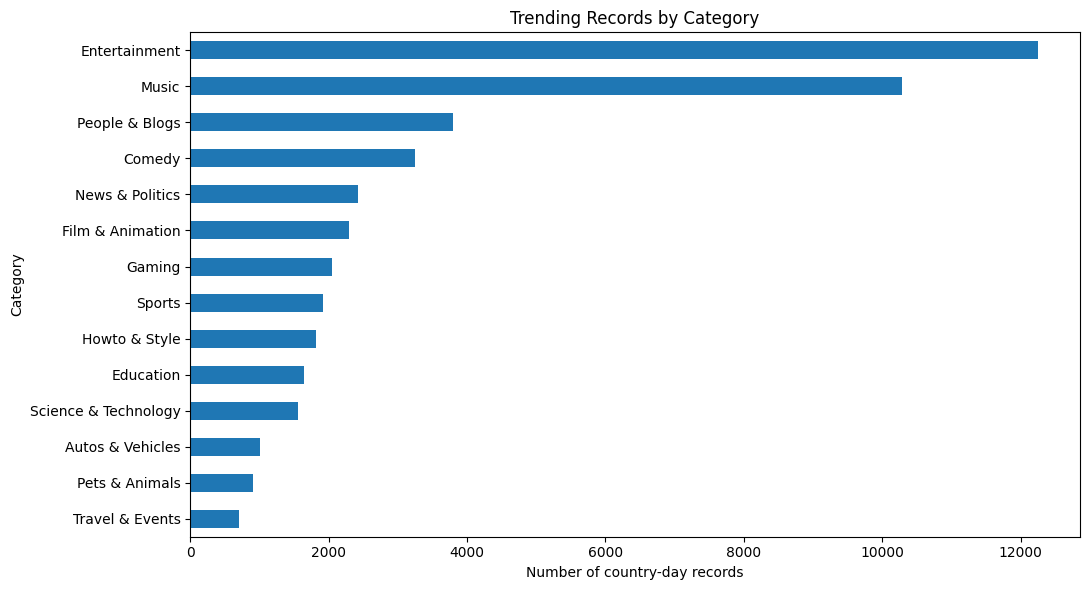

Interpretation: The longest bars identify categories that contribute the most trending country-day records. This is record frequency, not the number of distinct videos; repeated appearances are intentionally counted. A horizontal bar chart fits categorical labels and makes category ranking easy to compare.


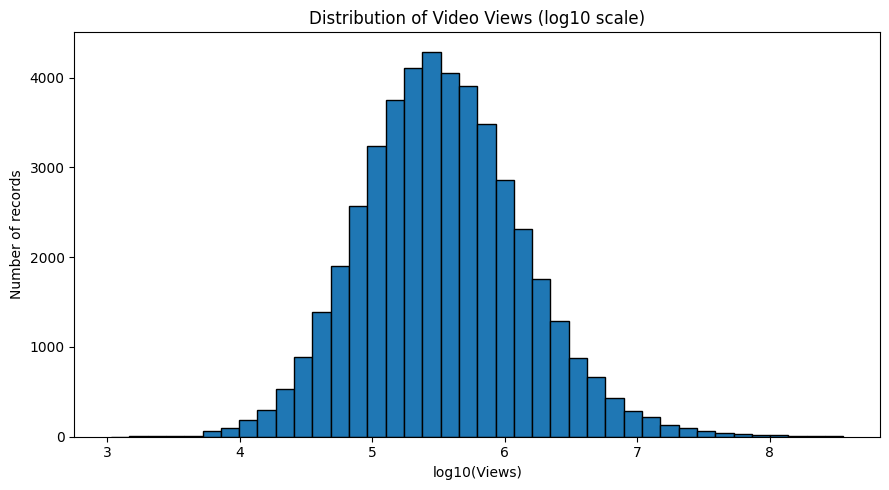

Interpretation: The histogram shows how view counts are distributed after logarithmic transformation, allowing both the dense lower range and the long high-view tail to be inspected. The log scale compresses extreme values without deleting them. A histogram is suitable because views are a numeric variable and the goal is to inspect its frequency distribution.


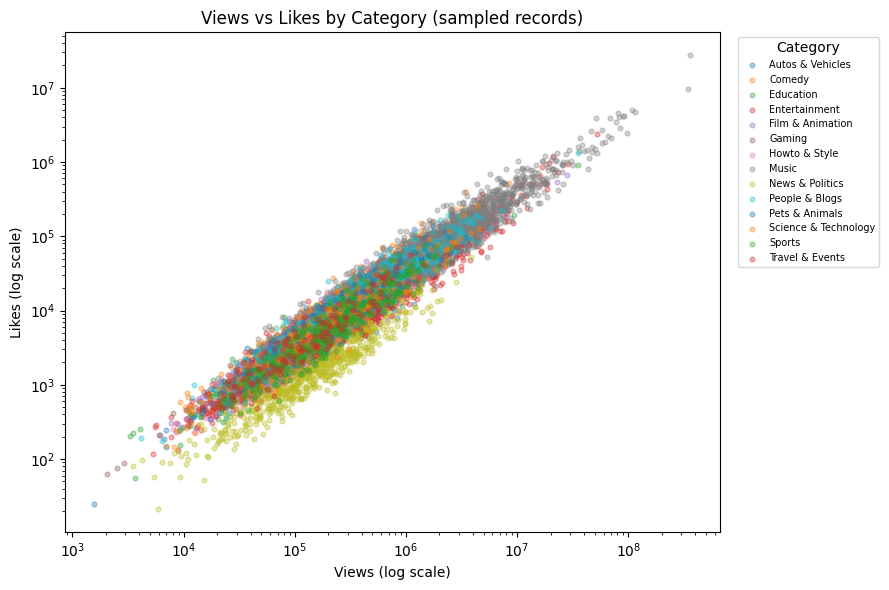

Interpretation: The scatter plot shows whether records with more views also tend to have more likes and whether the pattern varies by category. A log scale helps reveal structure across several orders of magnitude; the plotted sample is for readability only. A scatter plot fits two quantitative variables and exposes association, spread and unusual observations.


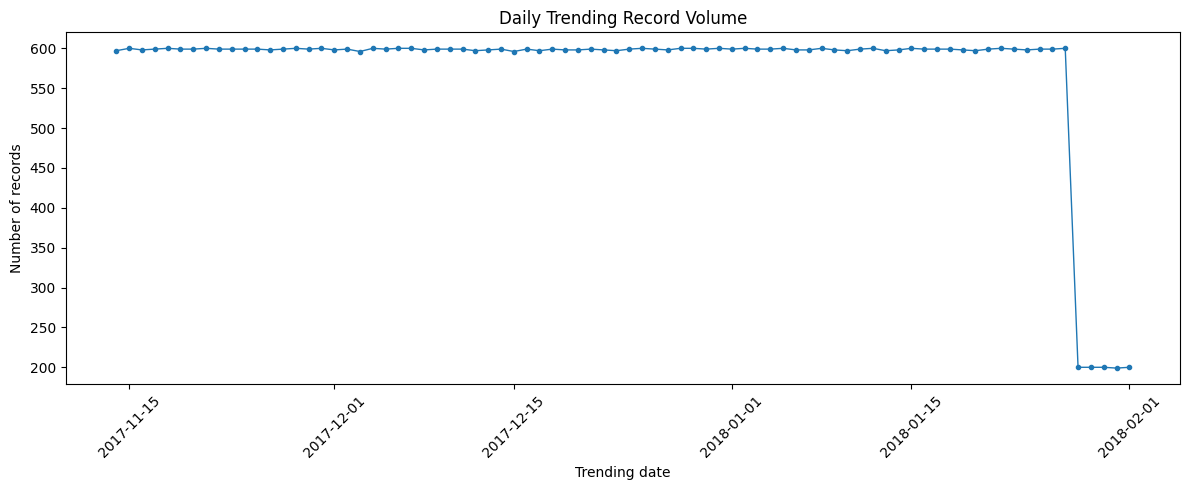

Interpretation: The line shows how the volume of observed trending records changes over the dataset's date window. Spikes and dips may reflect snapshot coverage or country-file availability as well as platform activity, so they should not automatically be interpreted as changes in total YouTube usage. A line chart fits an ordered date axis and emphasizes change over time.


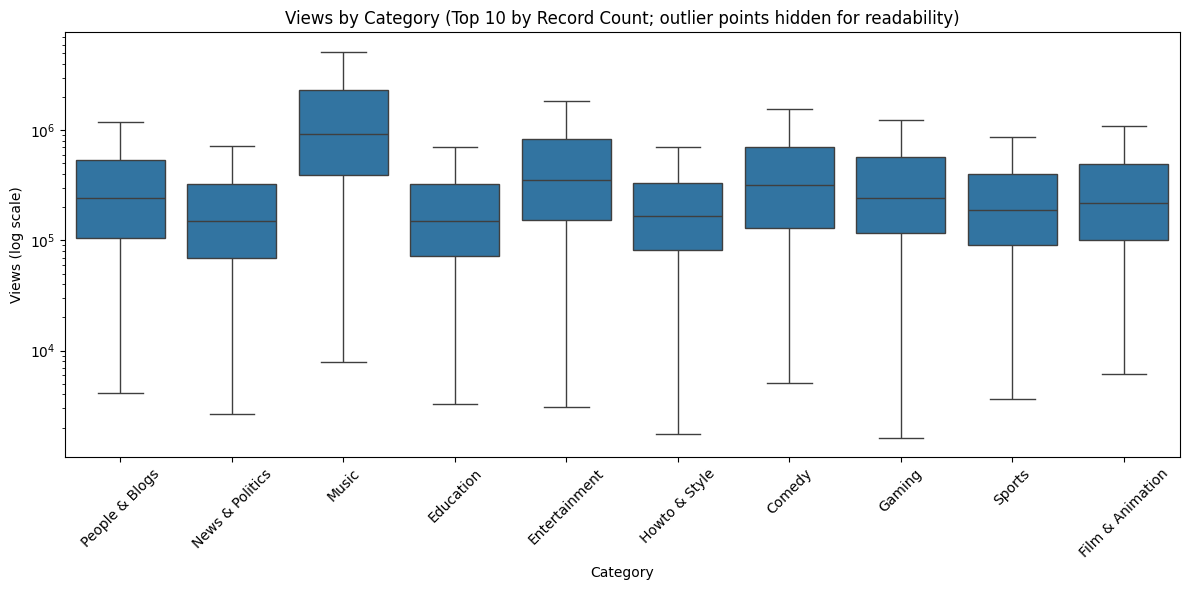

Interpretation: The box plots compare the median, interquartile range and spread of views across the ten most frequently represented categories. Individual outlier markers are hidden only to keep the chart readable; the observations remain in the dataset and in the statistical analysis. A box plot fits numeric values grouped by category and supports robust comparisons of center and spread.


In [3]:
# Chart 1: record counts by category
category_counts = clean["category"].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
category_counts.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Trending Records by Category")
ax.set_xlabel("Number of country-day records")
ax.set_ylabel("Category")
plt.tight_layout(); plt.show()
print("Interpretation: The longest bars identify categories that contribute the most trending country-day records. This is record frequency, not the number of distinct videos; repeated appearances are intentionally counted. A horizontal bar chart fits categorical labels and makes category ranking easy to compare.")

# Chart 2: log-scaled views distribution
views_positive = clean.loc[clean["views"].gt(0), "views"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(np.log10(views_positive), bins=40, edgecolor="black")
ax.set_title("Distribution of Video Views (log10 scale)")
ax.set_xlabel("log10(Views)")
ax.set_ylabel("Number of records")
plt.tight_layout(); plt.show()
print("Interpretation: The histogram shows how view counts are distributed after logarithmic transformation, allowing both the dense lower range and the long high-view tail to be inspected. The log scale compresses extreme values without deleting them. A histogram is suitable because views are a numeric variable and the goal is to inspect its frequency distribution.")

# Chart 3: views vs likes scatter (sample for legibility)
scatter_data = clean[["views", "likes", "category"]].dropna()
if len(scatter_data) > 12000:
    scatter_data = scatter_data.sample(12000, random_state=SEED)
fig, ax = plt.subplots(figsize=(9, 6))
for category, grp in scatter_data.groupby("category"):
    ax.scatter(grp["views"], grp["likes"], s=12, alpha=0.35, label=category)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Views vs Likes by Category (sampled records)")
ax.set_xlabel("Views (log scale)"); ax.set_ylabel("Likes (log scale)")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.tight_layout(); plt.show()
print("Interpretation: The scatter plot shows whether records with more views also tend to have more likes and whether the pattern varies by category. A log scale helps reveal structure across several orders of magnitude; the plotted sample is for readability only. A scatter plot fits two quantitative variables and exposes association, spread and unusual observations.")

# Chart 4: daily trending record counts
daily_counts = clean.groupby("trending_date").size().sort_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_counts.index, daily_counts.values, marker=".", linewidth=1)
ax.set_title("Daily Trending Record Volume")
ax.set_xlabel("Trending date"); ax.set_ylabel("Number of records")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print("Interpretation: The line shows how the volume of observed trending records changes over the dataset's date window. Spikes and dips may reflect snapshot coverage or country-file availability as well as platform activity, so they should not automatically be interpreted as changes in total YouTube usage. A line chart fits an ordered date axis and emphasizes change over time.")

# Chart 5: views by category (top 10 categories)
top_categories = clean["category"].value_counts().head(10).index
box_data = clean.loc[clean["category"].isin(top_categories) & clean["views"].gt(0), ["category", "views"]].copy()
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=box_data, x="category", y="views", ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_title("Views by Category (Top 10 by Record Count; outlier points hidden for readability)")
ax.set_xlabel("Category"); ax.set_ylabel("Views (log scale)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("Interpretation: The box plots compare the median, interquartile range and spread of views across the ten most frequently represented categories. Individual outlier markers are hidden only to keep the chart readable; the observations remain in the dataset and in the statistical analysis. A box plot fits numeric values grouped by category and supports robust comparisons of center and spread.")

## 4. Interactive charts — Plotly (two charts)

Hover over marks for detail. Large datasets are sampled for interactive responsiveness; aggregate charts use the full cleaned data.

In [4]:
# Interactive chart 1: views vs likes colored by category, title on hover
plotly_scatter = clean[["views", "likes", "category", "title", "country"]].dropna(subset=["views", "likes"]).copy()
if len(plotly_scatter) > 15000:
    plotly_scatter = plotly_scatter.sample(15000, random_state=SEED)
fig = px.scatter(plotly_scatter, x="views", y="likes", color="category", hover_name="title", hover_data=["country"], log_x=True, log_y=True, title="Interactive Views vs Likes by Category")
fig.update_layout(xaxis_title="Views (log scale)", yaxis_title="Likes (log scale)")
fig.show()
print("Interpretation: The interactive scatter lets the analyst inspect individual video titles and country context while comparing views and likes across categories. Clusters and exceptions are easier to investigate by hovering than in a static plot. An interactive scatter is appropriate for two numeric measures with categorical color and record-level hover details.")

# Interactive chart 2: mean views by category and country
country_category_views = (clean.dropna(subset=["views"]).groupby(["country", "category"], as_index=False)["views"].mean())
fig = px.bar(country_category_views, x="category", y="views", color="country", barmode="group", title="Average Views by Category Across Countries")
fig.update_layout(xaxis_title="Category", yaxis_title="Average views", xaxis_tickangle=-35)
fig.show()
print("Interpretation: The grouped bars compare average views for the same category across US, GB and IN records. Means can be influenced by extreme viral videos, so the chart should be read alongside the median and distribution analysis. A grouped bar chart fits a numeric summary compared across two categorical dimensions: category and country.")

Interpretation: The interactive scatter lets the analyst inspect individual video titles and country context while comparing views and likes across categories. Clusters and exceptions are easier to investigate by hovering than in a static plot. An interactive scatter is appropriate for two numeric measures with categorical color and record-level hover details.


Interpretation: The grouped bars compare average views for the same category across US, GB and IN records. Means can be influenced by extreme viral videos, so the chart should be read alongside the median and distribution analysis. A grouped bar chart fits a numeric summary compared across two categorical dimensions: category and country.


## 5. Distributions, skewness and IQR outliers

Mode is reported as the smallest mode if multiple values tie; this tie rule is stated for reproducibility. Skewness is concluded from mean/median/mode ordering as requested.

In [5]:
def distribution_summary(series, name):
    x = pd.to_numeric(series, errors="coerce").dropna()
    modes = x.mode()
    mode_value = modes.iloc[0] if not modes.empty else np.nan
    mean_value, median_value = x.mean(), x.median()
    if np.isclose(mean_value, median_value):
        skew = "approximately symmetric by mean/median comparison"
    elif mean_value > median_value:
        skew = "right-skewed (mean > median; mode ordering is also shown below)"
    else:
        skew = "left-skewed (mean < median; mode ordering is also shown below)"
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = int(((x < lower) | (x > upper)).sum())
    return {"metric": name, "n": len(x), "mean": mean_value, "median": median_value, "mode_smallest_if_tied": mode_value, "ordering": f"mean={mean_value:.3f}, median={median_value:.3f}, mode={mode_value:.3f}", "skew_conclusion": skew, "Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lower, "upper_fence": upper, "IQR_outlier_count": outlier_count, "decision": "KEEP: high values may be genuine viral observations and are relevant to content strategy; report their influence rather than deleting them."}

view_stats = distribution_summary(clean["views"], "views")
like_stats = distribution_summary(clean["likes"], "likes")
distribution_table = pd.DataFrame([view_stats, like_stats]).set_index("metric")
display(distribution_table.T)
print("Interpretation: Compare mean, median and mode for each metric. Mean above median is evidence of a right tail; mean below median indicates a left tail, while near-equality suggests symmetry. The mode ordering is included explicitly, but for highly discrete, large-count data the mode can be unstable and should be interpreted cautiously. IQR outliers are retained because viral extremes are part of the phenomenon being studied, not automatically data errors.")

metric,views,likes
n,45908,45896
mean,1180231.957546,45873.442631
median,318570.0,10213.0
mode_smallest_if_tied,16000.0,0.0
ordering,"mean=1180231.958, median=318570.000, mode=1600...","mean=45873.443, median=10213.000, mode=0.000"
skew_conclusion,right-skewed (mean > median; mode ordering is ...,right-skewed (mean > median; mode ordering is ...
Q1,129578.5,3656.0
Q3,823935.75,28989.25
IQR,694357.25,25333.25
lower_fence,-911957.375,-34343.875


Interpretation: Compare mean, median and mode for each metric. Mean above median is evidence of a right tail; mean below median indicates a left tail, while near-equality suggests symmetry. The mode ordering is included explicitly, but for highly discrete, large-count data the mode can be unstable and should be interpreted cautiously. IQR outliers are retained because viral extremes are part of the phenomenon being studied, not automatically data errors.


## 6. Correlation matrix and heatmap

The required numeric fields are included. The two strongest pairs are selected by absolute off-diagonal correlation, excluding self-correlations.

Correlation matrix:


,views,likes,dislikes,comment_count,days_to_trend
views,1.000,0.921,0.889,0.916,-0.014
likes,0.921,1.000,0.868,0.813,-0.013
dislikes,0.889,0.868,1.000,0.889,-0.012
comment_count,0.916,0.813,0.889,1.000,-0.014
days_to_trend,-0.014,-0.013,-0.012,-0.014,1.000


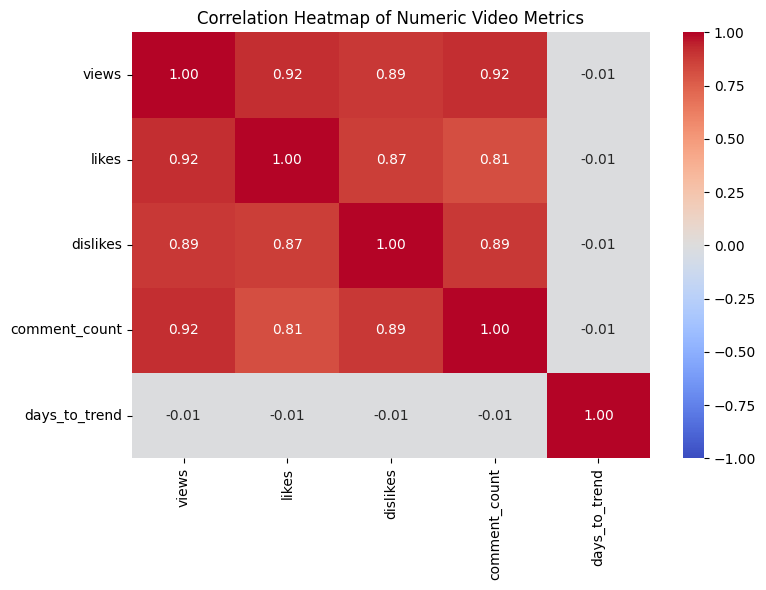

Two strongest absolute off-diagonal correlations:
views vs likes: r=0.921 (positive)
views vs comment_count: r=0.916 (positive)
Interpretation: The strongest pairs are ranked by absolute Pearson coefficient, so both positive and negative associations are considered. Correlation describes co-movement, not causal direction; for example, more likes may accompany more views because both can be influenced by exposure, age, topic and recommendation systems. Therefore correlation here does not prove that likes cause views. A heatmap is suitable because it displays the full pairwise numeric correlation matrix in one compact, color-coded view.


In [6]:
corr_cols = ["views", "likes", "dislikes", "comment_count", "days_to_trend"]
corr_data = clean[corr_cols].apply(pd.to_numeric, errors="coerce")
corr = corr_data.corr(method="pearson", min_periods=2)
print("Correlation matrix:")
display(corr.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Video Metrics")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
strongest = upper.reindex(upper.abs().sort_values(ascending=False).index).head(2)
print("Two strongest absolute off-diagonal correlations:")
for (a, b), value in strongest.items():
    direction = "positive" if value > 0 else "negative"
    print(f"{a} vs {b}: r={value:.3f} ({direction})")
print("Interpretation: The strongest pairs are ranked by absolute Pearson coefficient, so both positive and negative associations are considered. Correlation describes co-movement, not causal direction; for example, more likes may accompany more views because both can be influenced by exposure, age, topic and recommendation systems. Therefore correlation here does not prove that likes cause views. A heatmap is suitable because it displays the full pairwise numeric correlation matrix in one compact, color-coded view.")

## 7. Unique-video funnel

One record per `video_id` is created. Peak views and peak comments are maxima across all observed countries and trending days. Each stage is nested inside the previous stage; conversion is relative to the preceding stage.

In [7]:
video_level = (clean.groupby("video_id", as_index=False)
    .agg(peak_views=("views", "max"), peak_comments=("comment_count", "max"),
         first_trending_date=("trending_date", "min"), countries_seen=("country", "nunique"),
         category=("category", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown")))
video_level = video_level.dropna(subset=["peak_views", "first_trending_date"]).copy()
all_n = len(video_level)
median_peak = video_level["peak_views"].median()
p90_peak = video_level["peak_views"].quantile(0.90)
stage1 = video_level
stage2 = stage1.loc[stage1["peak_views"] > median_peak]
stage3 = stage2.loc[stage2["peak_views"] > p90_peak]
stage4 = stage3.loc[stage3["peak_comments"].ge(1000)]
stages = [("All unique videos that ever trended", stage1), ("Above median peak views", stage2), ("Above 90th percentile peak views", stage3), ("1,000+ peak comments", stage4)]
rows=[]; prev=len(stage1)
for i,(label, frame) in enumerate(stages):
    count=len(frame); conversion=100*count/prev if prev else np.nan
    overall=100*count/all_n if all_n else np.nan
    rows.append({"stage":label,"video_count":count,"conversion_from_previous_percent":conversion,"conversion_from_all_videos_percent":overall})
    prev=count
funnel = pd.DataFrame(rows)
display(funnel.round(2))
# Largest drop-off is measured by absolute number lost between consecutive stages.
drops=[]
for i in range(1,len(rows)):
    drops.append((rows[i-1]["stage"]+" → "+rows[i]["stage"], rows[i-1]["video_count"]-rows[i]["video_count"]))
largest_drop = max(drops, key=lambda x:x[1]) if drops else ("N/A",0)
print(f"Peak-view thresholds: median={median_peak:,.0f}; 90th percentile={p90_peak:,.0f}")
print(f"Largest absolute drop-off: {largest_drop[0]} ({largest_drop[1]:,} videos lost).")
print("Interpretation: The largest drop-off identifies the strictest filter in absolute video count, while the conversion columns show the share that progresses through each nested stage. A large loss at the peak-view thresholds indicates that high reach is concentrated in a relatively small subset; a further loss at the comment threshold indicates that high reach does not guarantee deep comment activity. Counts depend on the supplied snapshot and these explicit threshold definitions.")

,stage,video_count,conversion_from_previous_percent,conversion_from_all_videos_percent
0,All unique videos that ever trended,14688,100.00,100.0
1,Above median peak views,7344,50.00,50.0
2,Above 90th percentile peak views,1469,20.00,10.0
3,"1,000+ peak comments",1440,98.03,9.8


Peak-view thresholds: median=265,290; 90th percentile=1,646,845
Largest absolute drop-off: All unique videos that ever trended → Above median peak views (7,344 videos lost).
Interpretation: The largest drop-off identifies the strictest filter in absolute video count, while the conversion columns show the share that progresses through each nested stage. A large loss at the peak-view thresholds indicates that high reach is concentrated in a relatively small subset; a further loss at the comment threshold indicates that high reach does not guarantee deep comment activity. Counts depend on the supplied snapshot and these explicit threshold definitions.


## 8. Retention-style analysis: trending lifespan

Day 1 is the first observed trending date for each unique video. Day N retention means the video appears in at least one of the three country files on the exact calendar date `first_trending_date + (N-1)`.

,day,videos_present,cohort_size,retention_percent
0,1,14688,14688,100.00
1,2,9230,14688,62.84
2,3,6142,14688,41.82
3,5,2872,14688,19.55
4,7,1476,14688,10.05


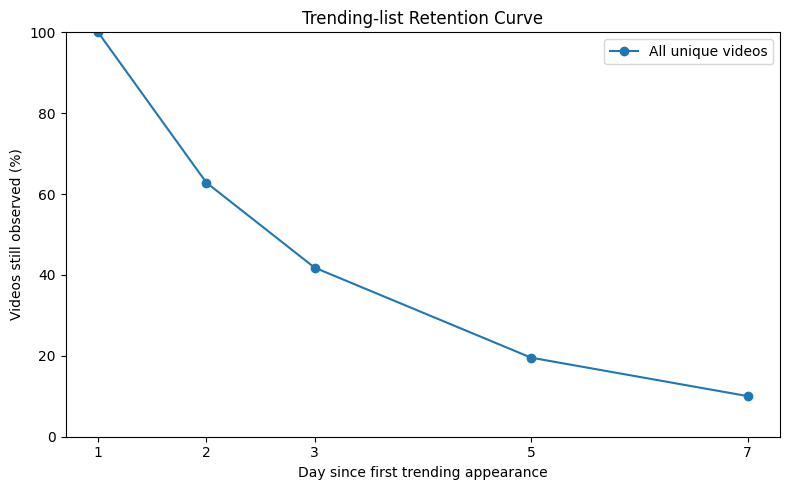

Interpretation: The curve measures the share of unique videos observed again on exact calendar offsets after their first trending date. A steep early decline means many videos are short-lived in the observed list; a flatter tail indicates a smaller group with longer persistence. Exact-date measurement is transparent but can undercount videos when snapshots have gaps. A line chart is suitable because retention is a percentage measured at ordered time points after first appearance.


Country comparison (day 2):


,country,unique_videos,day2_present,day2_retention_percent
1,GB,4112,2830,68.82
0,US,5064,3281,64.79
2,IN,5871,3336,56.82


Interpretation: Country-specific day-2 retention compares videos that first trended in each country's file and checks whether they appeared there again the next calendar day. The highest percentage indicates stronger observed next-day persistence in this sample, while the lowest indicates more one-day appearances. Category-level lifespan can also be explored using the next table; these are observed list patterns, not viewer-level retention.


Categories with highest multi-day presence (minimum 20 videos):


,category,unique_videos,multi_day_videos,multi_day_share_percent
7,Music,1882,1518,80.66
3,Entertainment,3385,2402,70.96
1,Comedy,1128,740,65.60
9,People & Blogs,1330,843,63.38
5,Gaming,767,484,63.10
4,Film & Animation,827,506,61.19
12,Sports,797,472,59.22
6,Howto & Style,742,436,58.76
2,Education,653,379,58.04
0,Autos & Vehicles,415,238,57.35


In [8]:
unique_first = clean.groupby("video_id")["trending_date"].min().rename("first_date")
observed = clean[["video_id", "trending_date", "country", "category"]].drop_duplicates()
observed_dates = observed.groupby("video_id")["trending_date"].agg(lambda s: set(pd.to_datetime(s).dt.normalize()))
retention_days = [1,2,3,5,7]
retention_rows=[]
for day in retention_days:
    offset = day - 1
    retained = 0
    for vid, first_date in unique_first.items():
        date_set = observed_dates.get(vid, set())
        target = pd.Timestamp(first_date).normalize() + pd.Timedelta(days=offset)
        retained += int(target in date_set)
    retention_rows.append({"day":day,"videos_present":retained,"cohort_size":len(unique_first),"retention_percent":100*retained/len(unique_first) if len(unique_first) else np.nan})
retention = pd.DataFrame(retention_rows)
display(retention.round(2))
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(retention["day"], retention["retention_percent"], marker="o", label="All unique videos")
ax.set_title("Trending-list Retention Curve")
ax.set_xlabel("Day since first trending appearance"); ax.set_ylabel("Videos still observed (%)")
ax.set_xticks(retention_days); ax.set_ylim(0,100); ax.legend()
plt.tight_layout(); plt.show()
print("Interpretation: The curve measures the share of unique videos observed again on exact calendar offsets after their first trending date. A steep early decline means many videos are short-lived in the observed list; a flatter tail indicates a smaller group with longer persistence. Exact-date measurement is transparent but can undercount videos when snapshots have gaps. A line chart is suitable because retention is a percentage measured at ordered time points after first appearance.")

# Compare countries using country-specific first appearance and exact day-2 presence.
country_retention=[]
for country in COUNTRIES:
    sub=clean.loc[clean["country"].eq(country)]
    first=sub.groupby("video_id")["trending_date"].min()
    dates=sub.groupby("video_id")["trending_date"].agg(lambda s:set(pd.to_datetime(s).dt.normalize()))
    kept=sum((pd.Timestamp(d).normalize()+pd.Timedelta(days=1)) in dates.get(v,set()) for v,d in first.items())
    country_retention.append({"country":country,"unique_videos":len(first),"day2_present":kept,"day2_retention_percent":100*kept/len(first) if len(first) else np.nan})
country_retention = pd.DataFrame(country_retention).sort_values("day2_retention_percent",ascending=False)
print("Country comparison (day 2):")
display(country_retention.round(2))
print("Interpretation: Country-specific day-2 retention compares videos that first trended in each country's file and checks whether they appeared there again the next calendar day. The highest percentage indicates stronger observed next-day persistence in this sample, while the lowest indicates more one-day appearances. Category-level lifespan can also be explored using the next table; these are observed list patterns, not viewer-level retention.")

# Category comparison: share of video-category assignments with >=2 distinct trending dates globally.
video_category = clean.groupby("video_id").agg(category=("category",lambda s:s.mode().iloc[0] if not s.mode().empty else "Unknown"), observed_days=("trending_date","nunique")).reset_index()
category_life = video_category.groupby("category").agg(unique_videos=("video_id","nunique"),multi_day_videos=("observed_days",lambda s:int((s>=2).sum()))).reset_index()
category_life["multi_day_share_percent"] = 100*category_life["multi_day_videos"]/category_life["unique_videos"]
category_life = category_life.sort_values("multi_day_share_percent",ascending=False)
print("Categories with highest multi-day presence (minimum 20 videos):")
display(category_life.loc[category_life["unique_videos"].ge(20)].head(10).round(2))

## 9. Weekly cohort comparison

Cohorts are defined by the calendar week of each unique video's first trending date. Average observed lifespan is the number of distinct calendar dates on which the video appears anywhere in the combined country data.

,cohort_week,video_count,average_peak_views,median_peak_views,average_observed_lifespan_days
0,2017-11-13/2017-11-19,1579,1076818.77,269792.0,3.39
1,2017-11-20/2017-11-26,1279,1307433.78,274021.0,3.38
2,2017-11-27/2017-12-03,1245,1126371.54,267984.0,3.33
3,2017-12-04/2017-12-10,1256,877542.13,280613.5,3.34
4,2017-12-11/2017-12-17,1262,1228220.45,274023.5,3.11
5,2017-12-18/2017-12-24,1323,919946.64,269138.0,3.18
6,2017-12-25/2017-12-31,1272,937139.09,277671.0,3.15
7,2018-01-01/2018-01-07,1347,1267810.97,245696.0,3.12
8,2018-01-08/2018-01-14,1356,833168.05,281117.5,3.14
9,2018-01-15/2018-01-21,1320,653156.67,266344.5,3.02


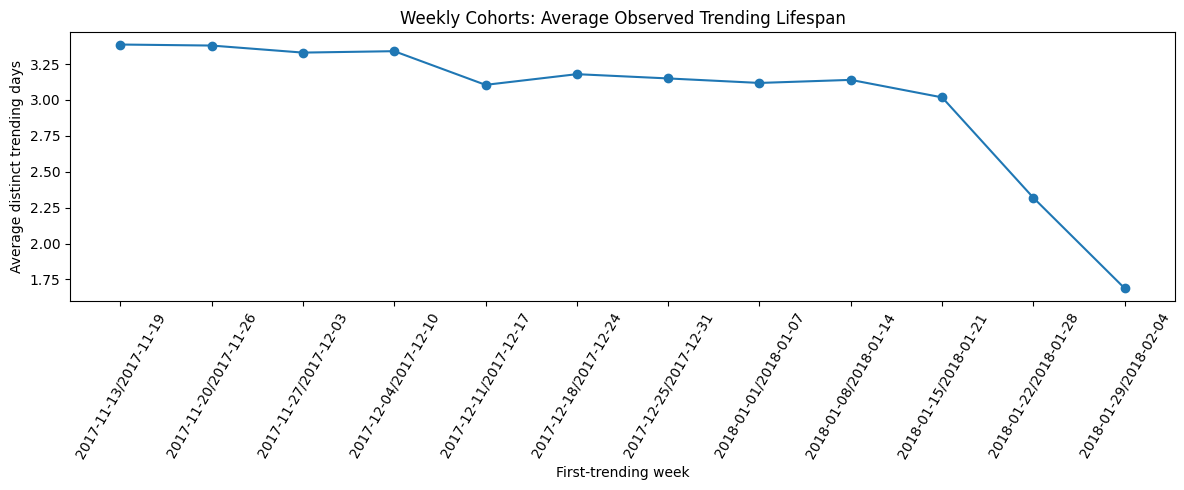

Largest cohort: 2017-11-13/2017-11-19 (n=1579). Smallest cohort: 2018-01-29/2018-02-04 (n=253). Highest average lifespan: 2017-11-13/2017-11-19 (3.39 days; n=1579).
Interpretation: The cohort table and line compare average observed trending lifespan for videos grouped by their first-trending week. Any unusually high or low cohort should be checked against its sample size: small cohorts can show unstable averages, and cohorts near the dataset boundaries may have truncated follow-up. The line chart fits the ordered weekly cohort axis and makes temporal differences visible. Because cohort sizes differ, interpret averages together with the video-count column rather than treating every point as equally reliable.


In [9]:
video_dates = clean.groupby("video_id").agg(first_date=("trending_date","min"), lifespan_days=("trending_date","nunique"), peak_views=("views","max")).reset_index()
video_dates["cohort_week"] = video_dates["first_date"].dt.to_period("W").astype(str)
cohort = video_dates.groupby("cohort_week").agg(video_count=("video_id","nunique"), average_peak_views=("peak_views","mean"), median_peak_views=("peak_views","median"), average_observed_lifespan_days=("lifespan_days","mean")).reset_index()
display(cohort.round(2))
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(cohort["cohort_week"], cohort["average_observed_lifespan_days"], marker="o")
ax.set_title("Weekly Cohorts: Average Observed Trending Lifespan")
ax.set_xlabel("First-trending week"); ax.set_ylabel("Average distinct trending days")
ax.tick_params(axis="x", rotation=60); plt.tight_layout(); plt.show()
if len(cohort):
    largest_cohort = cohort.loc[cohort["video_count"].idxmax()]
    min_cohort = cohort.loc[cohort["video_count"].idxmin()]
    max_life = cohort.loc[cohort["average_observed_lifespan_days"].idxmax()]
    print(f"Largest cohort: {largest_cohort['cohort_week']} (n={int(largest_cohort['video_count'])}). Smallest cohort: {min_cohort['cohort_week']} (n={int(min_cohort['video_count'])}). Highest average lifespan: {max_life['cohort_week']} ({max_life['average_observed_lifespan_days']:.2f} days; n={int(max_life['video_count'])}).")
print("Interpretation: The cohort table and line compare average observed trending lifespan for videos grouped by their first-trending week. Any unusually high or low cohort should be checked against its sample size: small cohorts can show unstable averages, and cohorts near the dataset boundaries may have truncated follow-up. The line chart fits the ordered weekly cohort axis and makes temporal differences visible. Because cohort sizes differ, interpret averages together with the video-count column rather than treating every point as equally reliable.")

## 10. Content strategy briefing (5–8 sentences)

The final briefing below is assembled from the actual computed tables. It includes category concentration, time-to-trend, persistence, country differences and a limitation.

In [10]:
# Evidence-backed briefing values
top_cat = category_counts.index[0] if len(category_counts) else "Unknown"
top_cat_n = int(category_counts.iloc[0]) if len(category_counts) else 0
top_cat_share = 100*top_cat_n/len(clean) if len(clean) else np.nan
valid_days = clean["days_to_trend"].dropna()
median_days_to_trend = valid_days.median() if len(valid_days) else np.nan
retention_lookup = retention.set_index("day")["retention_percent"].to_dict()
country_sorted = country_retention.sort_values("day2_retention_percent",ascending=False)
best_country = country_sorted.iloc[0] if len(country_sorted) else None
worst_country = country_sorted.iloc[-1] if len(country_sorted) else None
long_categories = category_life.loc[category_life["unique_videos"].ge(20)]
best_life_category = long_categories.iloc[0] if len(long_categories) else None
briefing = [
 f"Across {len(clean):,} cleaned country-day records from {', '.join(sorted(clean['country'].unique()))}, **{top_cat}** is the largest category by record volume with {top_cat_n:,} records ({top_cat_share:.1f}% of all records); this measures repeated trending appearances, not unique uploads.",
 f"The median time from publication to first trending appearance is {median_days_to_trend:.1f} calendar days, based on {len(valid_days):,} valid video-country observations; this describes only videos that entered the trending lists.",
 f"Of {len(unique_first):,} unique videos, day-2 retention is {retention_lookup.get(2,float('nan')):.1f}%, day-3 is {retention_lookup.get(3,float('nan')):.1f}%, day-5 is {retention_lookup.get(5,float('nan')):.1f}%, and day-7 is {retention_lookup.get(7,float('nan')):.1f}% when presence is checked on the exact calendar date.",
 f"The funnel's largest absolute loss is at **{largest_drop[0]}**, where {largest_drop[1]:,} videos do not progress; this suggests that high peak reach and/or sustained comment activity is concentrated in a smaller subset.",
 f"For country comparison, {best_country['country']} has the highest observed day-2 retention ({best_country['day2_retention_percent']:.1f}%) and {worst_country['country']} the lowest ({worst_country['day2_retention_percent']:.1f}%) in this sample." if best_country is not None else "Country-level day-2 retention could not be computed.",
 f"Among categories with at least 20 unique videos, {best_life_category['category']} has the highest share of videos appearing on two or more distinct trending dates ({best_life_category['multi_day_share_percent']:.1f}%)." if best_life_category is not None else "No category met the minimum sample size for the lifespan comparison.",
 "A key limitation is that the dataset contains only videos observed on trending lists during a fixed historical window; it has no denominator of videos that never trended, and edge-of-window videos may have incomplete follow-up."
]
for sentence in briefing:
    print(sentence)
print("\nSentence count:",len(briefing))
assert 5 <= len(briefing) <= 8, "Briefing must contain 5–8 sentences."

Across 45,908 cleaned country-day records from GB, IN, US, **Entertainment** is the largest category by record volume with 12,244 records (26.7% of all records); this measures repeated trending appearances, not unique uploads.
The median time from publication to first trending appearance is 1.0 calendar days, based on 45,908 valid video-country observations; this describes only videos that entered the trending lists.
Of 14,688 unique videos, day-2 retention is 62.8%, day-3 is 41.8%, day-5 is 19.6%, and day-7 is 10.0% when presence is checked on the exact calendar date.
The funnel's largest absolute loss is at **All unique videos that ever trended → Above median peak views**, where 7,344 videos do not progress; this suggests that high peak reach and/or sustained comment activity is concentrated in a smaller subset.
For country comparison, GB has the highest observed day-2 retention (68.8%) and IN the lowest (56.8%) in this sample.
Among categories with at least 20 unique videos, Music h

## 11. Final acceptance checklist

When run from top to bottom, this notebook provides: (1) combined profile, data types and affected-column missingness; (2) documented cleaning and category names; (3) at least five labelled Matplotlib charts with interpretations; (4) at least two labelled interactive Plotly charts with interpretations; (5) mean/median/mode, skew conclusions and IQR outlier decisions for views and likes; (6) correlation matrix, heatmap and strongest-pair interpretations; (7) the four-stage unique-video funnel and largest drop-off; (8) day 2/3/5/7 retention, curve and country/category comparisons; (9) weekly cohort analysis; and (10) a 5–8 sentence numeric content strategy briefing with a limitation.

**Important interpretation boundary:** all conclusions describe this supplied historical trending-list sample. They should not be generalized to all YouTube uploads or interpreted causally.